In [ ]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
# from torchvision.models import 
import torchvision.models as models


import string
from tqdm.notebook import tqdm
import cv2
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
import multiprocessing as mp

In [3]:
csv_data_path = "/kaggle/input/khmer-dataset-final/new_dataset/labels/labels.csv"
image_data_path = "/kaggle/input/khmer-dataset-final/new_dataset/images/Battambang/"

In [4]:
import pandas as pd

df = pd.read_csv(csv_data_path)
df


,image,label
0,Khmer_txt_1.png,ហេតុដូចម្តេចទើបមានការបង្កើតតាក់ស៊ីក្រហមឬTaxiRo...
1,Khmer_txt_2.png,និយាយទៅខ្ញុំបានសង្កេតពីការវិវត្តរបស់ប្រទេសកម្ព...
2,Khmer_txt_3.png,ខ្ញុំក៏សម្រេចចិត្តដំណើរការក្រុមហ៊ុនផ្តល់សេវាកម...
3,Khmer_txt_4.png,ហេតុអ្វីបានជាតាក់ស៊ីក្រហមត្រូវតែមាននៅកម្ពុជា?
4,Khmer_txt_5.png,តើចំណុចណាដែលធ្វើឲ្យតាក់ស៊ីក្រហមលេចធ្លោជាងក្រុម...
...,...,...
5244,Khmer_txt_5245.png,ការវេចខ្ចប់40HQ240HQ240HQ2
5245,Khmer_txt_5246.png,សេវាSathapana
5246,Khmer_txt_5247.png,សីលាបើមិនធ្វើមានតែអត់។
5247,Khmer_txt_5248.png,សំនួរការទាញយកhighdefinitionenvironmentv21.zip


In [8]:
df = df.dropna()

def clean_irrelevant(result):    
    result = result.replace('\u200b','')
    result = result.replace('/u200b','')

    # result = result.replace('quot ','')

    return result
df["label"] = df["label"].apply(clean_irrelevant)
# df = df[df['label'].apply(lambda x: len(x) <= 40)]
# df= df.reset_index(drop=True)

df

,image,label
0,Khmer_txt_1.png,ហេតុដូចម្តេចទើបមានការបង្កើតតាក់ស៊ីក្រហមឬTaxiRo...
1,Khmer_txt_2.png,និយាយទៅខ្ញុំបានសង្កេតពីការវិវត្តរបស់ប្រទេសកម្ព...
2,Khmer_txt_3.png,ខ្ញុំក៏សម្រេចចិត្តដំណើរការក្រុមហ៊ុនផ្តល់សេវាកម...
3,Khmer_txt_4.png,ហេតុអ្វីបានជាតាក់ស៊ីក្រហមត្រូវតែមាននៅកម្ពុជា?
4,Khmer_txt_5.png,តើចំណុចណាដែលធ្វើឲ្យតាក់ស៊ីក្រហមលេចធ្លោជាងក្រុម...
...,...,...
5244,Khmer_txt_5245.png,ការវេចខ្ចប់40HQ240HQ240HQ2
5245,Khmer_txt_5246.png,សេវាSathapana
5246,Khmer_txt_5247.png,សីលាបើមិនធ្វើមានតែអត់។
5247,Khmer_txt_5248.png,សំនួរការទាញយកhighdefinitionenvironmentv21.zip


In [9]:
def check_missing_values(df):
    """
    This function checks if there are any missing values in any row of the DataFrame.
    
    Parameters:
    df (pd.DataFrame): The DataFrame to check for missing values.
    
    Returns:
    bool: True if there are missing values in any row, False otherwise.
    """
    return df.isnull().any(axis=1).any()

if check_missing_values(df):
    print("There are missing values in the DataFrame.")
else:
    print("There are no missing values in the DataFrame.")

There are no missing values in the DataFrame.


In [10]:
datapath_all = df["image"].tolist()
label_all = df["label"].tolist()
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42)

# print((train_df["Label"]))
def check_missing_values(df):
    """
    This function checks if there are any missing values in any row of the DataFrame.
    
    Parameters:
    df (pd.DataFrame): The DataFrame to check for missing values.
    
    Returns:
    bool: True if there are missing values in any row, False otherwise.
    """
    return df.isnull().any(axis=1).any()
datapath_train = train_df["image"].tolist()
datapath_test = test_df["image"].tolist()

label_train = train_df["label"].tolist()
label_test = test_df["label"].tolist()
label_train[:5]

['ក្រសួងនេះបានឲ្យដឹងនៅក្នុងសេចក្ដីប្រកាសព័ត៌មានមួយថា៖',
 'ទំហំក្រឡា33x36x90mm',
 'វត្ថុត្រាប់តាមComment',
 'ឈ្មោះម៉ាកhanglongzhongtian',
 'ខ្ញុំទើបតែបានការងារថ្មីនៅទីក្រុងដូច្នេះខ្ញុំដើរទិញសំលៀកបំពាក់។']

In [11]:
datapath_train[:5]

['Khmer_txt_379.png',
 'Khmer_txt_4789.png',
 'Khmer_txt_3470.png',
 'Khmer_txt_2504.png',
 'Khmer_txt_1581.png']

In [12]:
print(len(label_train))
print(np.unique([len(image_fn.split(" ")[0]) for image_fn in label_train]))

4199
[ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24
 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 43 44 45 46 47 48
 49 50 51 52 53 54 55 56 57 58 59 60 61 62 63 64 65 66 67 68 69 70 71 72
 73 74 75 76 77 78 79 80 81 82 83 84]


In [13]:
cpu_count = mp.cpu_count()
print(cpu_count)

4


In [11]:
print(len(train_df), len(test_df))

2458 615


In [14]:
# image_ns = [image_fn.split(".")[0] for image_fn in label_all]
image_ns = [image_fn.split(" ")[0] for image_fn in label_all]


# image_ns = [image_fn[0] for image_fn in label_all]


image_ns = "".join(image_ns)
letters = sorted(list(set(list(image_ns))))
print(len(letters))
print(letters)

169
['!', '$', '%', '&', "'", '(', ')', ',', '-', '.', '/', '0', '1', '2', '3', '4', '5', '6', '7', '8', '9', ':', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', '[', ']', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z', '«', '»', 'ç', 'ក', 'ខ', 'គ', 'ឃ', 'ង', 'ច', 'ឆ', 'ជ', 'ឈ', 'ញ', 'ដ', 'ឋ', 'ឌ', 'ឍ', 'ណ', 'ត', 'ថ', 'ទ', 'ធ', 'ន', 'ប', 'ផ', 'ព', 'ភ', 'ម', 'យ', 'រ', 'ល', 'វ', 'ស', 'ហ', 'ឡ', 'អ', 'ឥ', 'ឦ', 'ឧ', 'ឩ', 'ឪ', 'ឫ', 'ឬ', 'ឭ', 'ឮ', 'ឯ', 'ឱ', 'ឲ', 'ា', 'ិ', 'ី', 'ឹ', 'ឺ', 'ុ', 'ូ', 'ួ', 'ើ', 'ឿ', 'ៀ', 'េ', 'ែ', 'ៃ', 'ោ', 'ៅ', 'ំ', 'ះ', 'ៈ', '៉', '៊', '់', '៌', '៍', '៎', '៏', '័', '្', '។', '៕', '៖', 'ៗ', '៛', '៝', '០', '១', '២', '៣', '៤', '៥', '៦', '៧', '៨', '៩']


In [15]:
character = [chr(i) for i in range(ord('A'), ord('Z') + 1)]
# print("Character")
# print(character)

#vocabulary = ["."]+["p"]+letters+character + ["g"]
# vocabulary = letters+character
vocabulary = letters


print(len(vocabulary))
# print(vocabulary)
idx2char = {k:v for k,v in enumerate(vocabulary, start=0)}
# print(idx2char)
char2idx = {v:k for k,v in idx2char.items()}
print("All Vocabs")
print(char2idx)

169
All Vocabs
{'!': 0, '$': 1, '%': 2, '&': 3, "'": 4, '(': 5, ')': 6, ',': 7, '-': 8, '.': 9, '/': 10, '0': 11, '1': 12, '2': 13, '3': 14, '4': 15, '5': 16, '6': 17, '7': 18, '8': 19, '9': 20, ':': 21, '?': 22, 'A': 23, 'B': 24, 'C': 25, 'D': 26, 'E': 27, 'F': 28, 'G': 29, 'H': 30, 'I': 31, 'J': 32, 'K': 33, 'L': 34, 'M': 35, 'N': 36, 'O': 37, 'P': 38, 'Q': 39, 'R': 40, 'S': 41, 'T': 42, 'U': 43, 'V': 44, 'W': 45, 'X': 46, 'Y': 47, 'Z': 48, '[': 49, ']': 50, 'a': 51, 'b': 52, 'c': 53, 'd': 54, 'e': 55, 'f': 56, 'g': 57, 'h': 58, 'i': 59, 'j': 60, 'k': 61, 'l': 62, 'm': 63, 'n': 64, 'o': 65, 'p': 66, 'q': 67, 'r': 68, 's': 69, 't': 70, 'u': 71, 'v': 72, 'w': 73, 'x': 74, 'y': 75, 'z': 76, '«': 77, '»': 78, 'ç': 79, 'ក': 80, 'ខ': 81, 'គ': 82, 'ឃ': 83, 'ង': 84, 'ច': 85, 'ឆ': 86, 'ជ': 87, 'ឈ': 88, 'ញ': 89, 'ដ': 90, 'ឋ': 91, 'ឌ': 92, 'ឍ': 93, 'ណ': 94, 'ត': 95, 'ថ': 96, 'ទ': 97, 'ធ': 98, 'ន': 99, 'ប': 100, 'ផ': 101, 'ព': 102, 'ភ': 103, 'ម': 104, 'យ': 105, 'រ': 106, 'ល': 107, 'វ': 108, 'ស':

In [16]:
batch_size = 16

In [17]:
class CAPTCHADataset(Dataset):
    
    def __init__(self, data_dir, image_fns):
        self.data_dir = data_dir
        self.image_fns = image_fns
        
    def __len__(self):
        return len(self.image_fns)
    
    def __getitem__(self, index):
        image_fn = self.image_fns[index]
        image_fp = os.path.join(self.data_dir, image_fn)
        #image_fp = image_fp + ".png"
        image = Image.open(image_fp).convert('RGB')
        image = self.transform(image)
#         text = image_fn.split(".")[0]
        text = df.loc[df['image']==image_fn,"label"].iloc[0]
#         print(text)
        
        return image, text
    
    def transform(self, image):
        
        transform_ops = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
        ])
        return transform_ops(image)

In [18]:
trainset = CAPTCHADataset(image_data_path, datapath_train) 
testset = CAPTCHADataset(image_data_path, datapath_test)
train_loader = DataLoader(trainset, batch_size=batch_size, num_workers=cpu_count, shuffle=True)
test_loader = DataLoader(testset, batch_size=batch_size, num_workers=cpu_count, shuffle=False)
print(len(train_loader), len(test_loader))

263 66


In [19]:
image_batch, text_batch = next(iter(train_loader))
print(image_batch.size(), text_batch)

torch.Size([16, 3, 100, 1400]) ('តើធ្វើដូចម្តេចដើម្បីដំឡើងSupremoForexដែលIndicator.mq4របស់FX?', 'ផ្ទុកឡើងវិញស្វ័យប្រវត្តិoptionradioneverreloadthecache', 'បណ្ណាគារឥន្រ្ទទេវីIndradeviBookshopខេត្តបាត់ដំបង', 'ព័ត៌មានល្បែងTADSName', 'ចន្លោះពេលពន្យាលំនាំដើមinfowhatsthis', 'ខ្ញុំធ្នឹមដែកថែបមម3201301032013010', 'បានប្រកួតជាមួយក្រុមចំនួនជាង', 'លោកLiYueអគ្គនាយករបស់ក្រុមហ៊ុនChinaMobileបានថ្លែងនៅក្នុងសេចក្ដីប្រកាសព័ត៌មាននេះថា៖', 'អ្នកផ្សេងទៀតWindowsVessoft', 'កម្មវិធីWhatsApp8618201980007', 'បើវាជាកៅស៊ូនោះនៅពេលយើងហាលថ្ងៃវានឹងមានរូបរាងដដែល»។', 'ធ្វើឱ្យទាន់សម័យចុងក្រោយខែកញ្ញា152019', 'នៅប្រទេសអង់គ្លេស', 'ប្រព័ន្ធហ្គាសLPGCNGល្អបំផុតដែលត្រូវបានផលិតដោយសមាសធាតុដ៏ល្អបំផុតនៅក្នុងទីផ្សារ។', 'ខែធ្នូ12015', 'ទាញយកOutlook1.3.17នៅក្នុងភាសាខ្មែរVessoft')


In [20]:
num_chars = len(char2idx)
print(num_chars)
rnn_hidden_size = 512
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

169
cuda


In [21]:
# class CRNN(nn.Module):
    
#     def __init__(self, num_chars, rnn_hidden_size=256, dropout=0.1):
        
#         super(CRNN, self).__init__()
#         self.num_chars = num_chars
#         self.rnn_hidden_size = rnn_hidden_size
#         self.dropout = dropout
        
#         # CNN Part 1
# #         resnet = models.resnet18(pretrained=True)
#         resnet = models.resnet50(pretrained=True)


# #         resnet_modules = list(resnet.children())[:-3]
#         resnet_modules = list(resnet.children())[:-2]


#         self.cnn_p1 = nn.Sequential(*resnet_modules)
        
#         # CNN Part 2
#         self.cnn_p2 = nn.Sequential(
#             nn.Conv2d(2048, 1024, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(1024),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p3 = nn.Sequential(
#             nn.Conv2d(1024, 512, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(512),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p4 = nn.Sequential(
#             nn.Conv2d(512, 256, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(256),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p5 = nn.Sequential(
#             nn.Conv2d(256, 128, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(128),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p6 = nn.Sequential(
#             nn.Conv2d(128, 64, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(64),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p7 = nn.Sequential(
#             nn.Conv2d(64, 32, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(32),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p8 = nn.Sequential(
#             nn.Conv2d(32, 16, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(16),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p9 = nn.Sequential(
#             nn.Conv2d(16, 8, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(8),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p10 = nn.Sequential(
#             nn.Conv2d(8, 4, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(4),
#             nn.ReLU(inplace=True),
# #             nn.MaxPool2d(kernel_size=(2, 2), stride=2)

#         )
        
#         self.cnn_p11 = nn.Sequential(
#             nn.Conv2d(4, 2, kernel_size=(3,3), stride=1, padding=1),
#             nn.BatchNorm2d(2),
#             nn.ReLU(inplace=True)
#         )
# #         self.linear1 = nn.Linear(1024, 256)


# #         self.linear1 = nn.Linear(7168, rnn_hidden_size)
# #         self.linear1 = nn.Linear(4096, 256)
# #         self.linear1 = nn.Linear(8192, rnn_hidden_size)
# #         self.linear1 = nn.Linear(1536, rnn_hidden_size)
#         self.linear1 = nn.Linear(8, rnn_hidden_size)


 
#         # RNN
#         self.rnn1 = nn.GRU(input_size=rnn_hidden_size, 
#                             hidden_size=rnn_hidden_size,
#                             bidirectional=True, 
#                             batch_first=True)
#         self.rnn2 = nn.GRU(input_size=rnn_hidden_size, 
#                             hidden_size=rnn_hidden_size,
#                             bidirectional=True, 
#                             batch_first=True)
#         self.rnn3 = nn.GRU(input_size=rnn_hidden_size, 
#                             hidden_size=rnn_hidden_size,
#                             bidirectional=True, 
#                             batch_first=True)
        
# #         self.rnn4 = nn.GRU(input_size=rnn_hidden_size, 
# #                             hidden_size=rnn_hidden_size,
# #                             bidirectional=True, 
# #                             batch_first=True)
# #         self.rnn5 = nn.GRU(input_size=rnn_hidden_size, 
# #                             hidden_size=rnn_hidden_size,
# #                             bidirectional=True, 
# #                             batch_first=True)
# #         self.rnn6 = nn.GRU(input_size=rnn_hidden_size, 
# #                             hidden_size=rnn_hidden_size,
# #                             bidirectional=True, 
# #                             batch_first=True)
# #         self.rnn7 = nn.GRU(input_size=rnn_hidden_size, 
# #                             hidden_size=rnn_hidden_size,
# #                             bidirectional=True, 
# #                             batch_first=True)
        
#         self.linear2 = nn.Linear(self.rnn_hidden_size*2, num_chars)
        
        
#     def forward(self, batch):
        
#         batch = self.cnn_p1(batch)
#         # print(batch.size()) # torch.Size([-1, 256, 4, 13])
        
#         batch = self.cnn_p2(batch) # [batch_size, channels, height, width]
#         # print(batch.size())# torch.Size([-1, 256, 4, 10])
        
#         batch = self.cnn_p3(batch)
#         batch = self.cnn_p4(batch)
#         batch = self.cnn_p5(batch)
#         batch = self.cnn_p6(batch)
#         batch = self.cnn_p7(batch)
#         batch = self.cnn_p8(batch)
#         batch = self.cnn_p9(batch)
#         batch = self.cnn_p10(batch)
#         batch = self.cnn_p11(batch)


      
#         batch = batch.permute(0, 3, 1, 2) # [batch_size, width, channels, height]
#         # print(batch.size()) # torch.Size([-1, 10, 256, 4])
         
#         batch_size = batch.size(0)
#         T = batch.size(1)
#         batch = batch.view(batch_size, T, -1) # [batch_size, T==width, num_features==channels*height]
#         # print(batch.size()) # torch.Size([-1, 10, 1024])
        
#         batch = self.linear1(batch)
#         # print(batch.size()) # torch.Size([-1, 10, 256])
        
#         batch, hidden = self.rnn1(batch)
#         feature_size = batch.size(2)
#         batch = batch[:, :, :feature_size//2] + batch[:, :, feature_size//2:]
#         # print(batch.size()) # torch.Size([-1, 10, 256])
        
#         batch, hidden = self.rnn2(batch)
#         feature_size = batch.size(2)
#         batch = batch[:, :, :feature_size//2] + batch[:, :, feature_size//2:]
        
# #         batch, hidden = self.rnn3(batch)
# #         feature_size = batch.size(2)
# #         batch = batch[:, :, :feature_size//2] + batch[:, :, feature_size//2:]
        
# #         batch, hidden = self.rnn4(batch)
# #         feature_size = batch.size(2)
# #         batch = batch[:, :, :feature_size//2] + batch[:, :, feature_size//2:]
        
#         batch, hidden = self.rnn3(batch)
        
        
#         # print(batch.size()) # torch.Size([-1, 10, 512])
        
#         batch = self.linear2(batch)
#         # print(batch.size()) # torch.Size([-1, 10, 20])
        
#         batch = batch.permute(1, 0, 2) # [T==10, batch_size, num_classes==num_features]
#         # print(batch.size()) # torch.Size([10, -1, 20])
        
#         return batch

# def weights_init(m):
#     classname = m.__class__.__name__
#     if type(m) in [nn.Linear, nn.Conv2d, nn.Conv1d]:
#         torch.nn.init.xavier_uniform_(m.weight)
#         if m.bias is not None:
#             m.bias.data.fill_(0.01)
#     elif classname.find('BatchNorm') != -1:
#         m.weight.data.normal_(1.0, 0.02)
#         m.bias.data.fill_(0)

class OCR_CNN_GRU(nn.Module):
    def __init__(self, num_chars=158, rnn_hidden_size=256, dropout=0.1):
        super(OCR_CNN_GRU, self).__init__()
        self.num_chars = num_chars
        self.rnn_hidden_size = rnn_hidden_size
        self.dropout = dropout
        
        # CNN layers
        self.cnn = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
            nn.Conv2d(64, 128, kernel_size=(3, 3), padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(128, 256, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(256),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(256, 512, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(512),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
            
#             nn.Conv2d(512, 1024, kernel_size=(3, 3), padding=1),
#             nn.BatchNorm2d(1024),
#             nn.ReLU(inplace=True),
#             nn.MaxPool2d(kernel_size=(2, 2), stride=2),
        )
        
        # Linear layer to reduce dimension before feeding into GRU
#         self.linear1 = nn.Linear(512 * 8, rnn_hidden_size)
        self.linear1 = nn.Linear(3200, rnn_hidden_size)


        
        # GRU layers
        self.gru = nn.GRU(
            input_size=rnn_hidden_size, 
            hidden_size=rnn_hidden_size, 
            num_layers=2, 
            bidirectional=True, 
            batch_first=True
        )
        
        # Output layer
        self.linear2 = nn.Linear(rnn_hidden_size * 2, num_chars)
        
    def forward(self, x):
        x = self.cnn(x)
        
        # Reshape from [batch_size, channels, height, width] to [batch_size, width, channels * height]
        batch_size, channels, height, width = x.size()
        x = x.permute(0, 3, 1, 2).contiguous().view(batch_size, width, -1)
        
        # Linear layer to reduce dimension
        x = self.linear1(x)
        
        # GRU layers
        x, _ = self.gru(x)
        
        # Output layer
        x = self.linear2(x)
        
        # Transpose to get the shape [sequence_length, batch_size, num_classes]
        x = x.transpose(0, 1)
        
        return x

def weights_init(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        nn.init.xavier_uniform_(m.weight)
        if m.bias is not None:
            m.bias.data.fill_(0.01)
    elif isinstance(m, nn.BatchNorm2d):
        m.weight.data.fill_(1.0)
        m.bias.data.fill_(0.01)




In [22]:
crnn = OCR_CNN_GRU(num_chars, rnn_hidden_size=rnn_hidden_size)
crnn.apply(weights_init)
crnn = crnn.to(device)
text_batch_logits = crnn(image_batch.to(device))
print(text_batch)
print(text_batch_logits.shape)

('តើធ្វើដូចម្តេចដើម្បីដំឡើងSupremoForexដែលIndicator.mq4របស់FX?', 'ផ្ទុកឡើងវិញស្វ័យប្រវត្តិoptionradioneverreloadthecache', 'បណ្ណាគារឥន្រ្ទទេវីIndradeviBookshopខេត្តបាត់ដំបង', 'ព័ត៌មានល្បែងTADSName', 'ចន្លោះពេលពន្យាលំនាំដើមinfowhatsthis', 'ខ្ញុំធ្នឹមដែកថែបមម3201301032013010', 'បានប្រកួតជាមួយក្រុមចំនួនជាង', 'លោកLiYueអគ្គនាយករបស់ក្រុមហ៊ុនChinaMobileបានថ្លែងនៅក្នុងសេចក្ដីប្រកាសព័ត៌មាននេះថា៖', 'អ្នកផ្សេងទៀតWindowsVessoft', 'កម្មវិធីWhatsApp8618201980007', 'បើវាជាកៅស៊ូនោះនៅពេលយើងហាលថ្ងៃវានឹងមានរូបរាងដដែល»។', 'ធ្វើឱ្យទាន់សម័យចុងក្រោយខែកញ្ញា152019', 'នៅប្រទេសអង់គ្លេស', 'ប្រព័ន្ធហ្គាសLPGCNGល្អបំផុតដែលត្រូវបានផលិតដោយសមាសធាតុដ៏ល្អបំផុតនៅក្នុងទីផ្សារ។', 'ខែធ្នូ12015', 'ទាញយកOutlook1.3.17នៅក្នុងភាសាខ្មែរVessoft')
torch.Size([350, 16, 169])


In [23]:
criterion = nn.CTCLoss(blank=0)
def encode_text_batch(text_batch):
    
    text_batch_targets_lens = [len(text) for text in text_batch]
    text_batch_targets_lens = torch.IntTensor(text_batch_targets_lens)
    
    text_batch_concat = "".join(text_batch)
    text_batch_targets = [char2idx[c] for c in text_batch_concat]
    text_batch_targets = torch.IntTensor(text_batch_targets)
    
    return text_batch_targets, text_batch_targets_lens

In [24]:
def compute_loss(text_batch, text_batch_logits):
    """
    text_batch: list of strings of length equal to batch size
    text_batch_logits: Tensor of size([T, batch_size, num_classes])
    """
    text_batch_logps = F.log_softmax(text_batch_logits, 2) # [T, batch_size, num_classes]  
    text_batch_logps_lens = torch.full(size=(text_batch_logps.size(1),), 
                                       fill_value=text_batch_logps.size(0), 
                                       dtype=torch.int32).to(device) # [batch_size] 
    #print(text_batch_logps.shape)
    #print(text_batch_logps_lens) 
    text_batch_targets, text_batch_targets_lens = encode_text_batch(text_batch)
    #print(text_batch_targets)
    #print(text_batch_targets_lens)
    loss = criterion(text_batch_logps, text_batch_targets, text_batch_logps_lens, text_batch_targets_lens)

    return loss

compute_loss(text_batch, text_batch_logits)

tensor(50.6775, device='cuda:0', grad_fn=<MeanBackward0>)

In [25]:
num_epochs = 20
lr = 1e-4
weight_decay = 1e-3
clip_norm = 5

In [26]:
optimizer = optim.Adam(crnn.parameters(), lr=lr, weight_decay=weight_decay)
lr_scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, verbose=True, patience=5)

In [27]:
import numpy as np
import torch.nn as nn
from tqdm.notebook import tqdm  # Use tqdm.notebook for better support in notebooks

# Assuming other necessary imports and initializations are already done

epoch_losses = []
iteration_losses = []
num_updates_epochs = []
validation_losses = []
best_val_loss = float('inf')
epochs_no_improve = 0

# Main training loop
for epoch in range(1, num_epochs + 1):
    epoch_loss_list = []
    num_updates_epoch = 0
    crnn.train()  # Set model to training mode

    # Training step with a single progress bar
    train_loader_tqdm = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} - Training", leave=True)
    for image_batch, text_batch in train_loader_tqdm:
        optimizer.zero_grad()
        text_batch_logits = crnn(image_batch.to(device))
        loss = compute_loss(text_batch, text_batch_logits)
        iteration_loss = loss.item()

        if np.isnan(iteration_loss) or np.isinf(iteration_loss):
            continue

        num_updates_epoch += 1
        iteration_losses.append(iteration_loss)
        epoch_loss_list.append(iteration_loss)
        loss.backward()
        nn.utils.clip_grad_norm_(crnn.parameters(), clip_norm)
        optimizer.step()

        # Update progress bar with the current loss
        train_loader_tqdm.set_postfix(loss=iteration_loss)

    epoch_loss = np.mean(epoch_loss_list)
    epoch_losses.append(epoch_loss)
    num_updates_epochs.append(num_updates_epoch)

    # Validation step with a single progress bar
    crnn.eval()  # Set model to evaluation mode
    with torch.no_grad():
        val_losses = []
        val_loader_tqdm = tqdm(test_loader, desc=f"Epoch {epoch}/{num_epochs} - Validation", leave=True)
        for image_batch, text_batch in val_loader_tqdm:
            text_batch_logits = crnn(image_batch.to(device))
            val_loss = compute_loss(text_batch, text_batch_logits)
            val_losses.append(val_loss.item())
            val_loader_tqdm.set_postfix(val_loss=val_loss.item())

        validation_loss = np.mean(val_losses)
    validation_losses.append(validation_loss)

    # Early stopping and saving the best model
    if validation_loss < best_val_loss:
        best_val_loss = validation_loss
        torch.save(crnn.state_dict(), '/kaggle/working/best_model.pth')  # Save the best model
        epochs_no_improve = 0  # Reset the counter for early stopping
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= num_epochs:
            print(f'Early stopping triggered after {epoch} epochs.')
            break  # Early stopping condition met

    print(f"Epoch: {epoch}    Loss: {epoch_loss:.4f}    NumUpdates: {num_updates_epoch}    ValLoss: {validation_loss:.4f}")
    lr_scheduler.step(validation_loss)


Epoch 1/20 - Training:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 1/20 - Validation:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch: 1    Loss: 4.3189    NumUpdates: 263    ValLoss: 2.1221


Epoch 2/20 - Training:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 2/20 - Validation:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch: 2    Loss: 1.5247    NumUpdates: 263    ValLoss: 1.0635


... (50 outputs left out)

Epoch: 19    Loss: 0.1058    NumUpdates: 263    ValLoss: 0.2334


Epoch 20/20 - Training:   0%|          | 0/263 [00:00<?, ?it/s]

Epoch 20/20 - Validation:   0%|          | 0/66 [00:00<?, ?it/s]

Epoch: 20    Loss: 0.1023    NumUpdates: 263    ValLoss: 0.2414


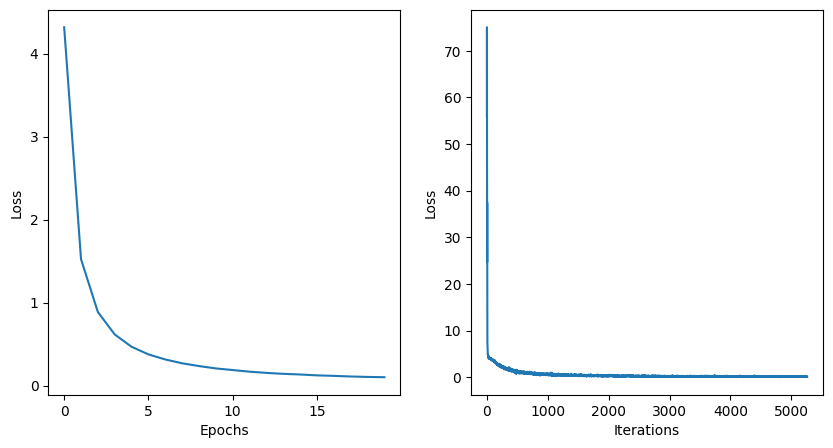

In [28]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

ax1.plot(epoch_losses)
ax1.set_xlabel("Epochs")
ax1.set_ylabel("Loss")

ax2.plot(iteration_losses)
ax2.set_xlabel("Iterations")
ax2.set_ylabel("Loss")

plt.show()

In [29]:
def decode_predictions(text_batch_logits):

    text_batch_tokens = F.softmax(text_batch_logits, 2).argmax(2) # [T, batch_size]
    text_batch_tokens = text_batch_tokens.numpy().T # [batch_size, T]

    text_batch_tokens_new = []
    for text_tokens in text_batch_tokens:
        text = [idx2char[idx] for idx in text_tokens]
        text = "".join(text)
        text_batch_tokens_new.append(text)

    return text_batch_tokens_new

In [30]:
results_train = pd.DataFrame(columns=['actual', 'prediction'])
train_loader = DataLoader(trainset, batch_size=16, num_workers=1, shuffle=False)
with torch.no_grad():
    for image_batch, text_batch in tqdm(train_loader, leave=True):
        text_batch_logits = crnn(image_batch.to(device)) # [T, batch_size, num_classes==num_features]
        text_batch_pred = decode_predictions(text_batch_logits.cpu())
        #print(text_batch, text_batch_pred)
        df = pd.DataFrame(columns=['actual', 'prediction'])
        df['actual'] = text_batch
        df['prediction'] = text_batch_pred
        results_train = pd.concat([results_train, df])
results_train = results_train.reset_index(drop=True)

  0%|          | 0/263 [00:00<?, ?it/s]

In [31]:
def remove_duplicates(text):
    if len(text) > 1:
        letters = [text[0]] + [letter for idx, letter in enumerate(text[1:], start=1) if text[idx] != text[idx-1]]
    elif len(text) == 1:
        letters = [text[0]]
    else:
        return ""
    return "".join(letters)

def correct_prediction(word):
    parts = word.split("-")
    parts = [remove_duplicates(part) for part in parts]
    corrected_word = "".join(parts)
    return corrected_word

In [32]:
results_train['prediction_corrected'] = results_train['prediction'].apply(correct_prediction)
results_train.head()

,actual,prediction,prediction_corrected
0,ក្រសួងនេះបានឲ្យដឹងនៅក្នុងសេចក្ដីប្រកាសព័ត៌មានម...,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ក្រ!សួង!នេះ!បានឲ្យដឹង!នៅក្នុងសេចក្ដីប្រកាស!ព័...
1,ទំហំក្រឡា33x36x90mm,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ទំហំក្រឡា!3!3!x!36!x!9!0!m!m!
2,វត្ថុត្រាប់តាមComment,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!វត្តុត្រាប់តាម!C!o!m!m!e!nt!
3,ឈ្មោះម៉ាកhanglongzhongtian,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ឈ្មោះម៉ាក!h!an!g!lon!g!z!hon!gtia!n!
4,ខ្ញុំទើបតែបានការងារថ្មីនៅទីក្រុងដូច្នេះខ្ញុំដើ...,!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!!...,!ខ្ញុំទើប!តែបាន!ការងារថ្មីនៅទីក្រុងដូច្នេះញ្ុដ...


In [33]:
import os
import torch
import pandas as pd
from PIL import Image
import torch.nn.functional as F
from torchvision import transforms

# Define the transformation operations
transform_ops = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225))
])

# Function to remove duplicates in the predicted text
def remove_duplicates(text):
    if len(text) > 1:
        letters = [text[0]] + [letter for idx, letter in enumerate(text[1:], start=1) if text[idx] != text[idx-1]]
    elif len(text) == 1:
        letters = [text[0]]
    else:
        return ""
    return "".join(letters)

# Function to correct the predicted word
def correct_prediction(word):
    parts = word.split("-")
    parts = [remove_duplicates(part) for part in parts]
    corrected_word = "".join(parts)
    return corrected_word

# Function to decode predictions from logits
def decode_predictions(text_batch_logits):
    text_batch_tokens = F.softmax(text_batch_logits, 2).argmax(2)  # [T, batch_size]
    text_batch_tokens = text_batch_tokens.numpy().T  # [batch_size, T]

    text_batch_tokens_new = []
    for text_tokens in text_batch_tokens:
        text = [idx2char[idx] for idx in text_tokens]
        text = "".join(text)
        text_batch_tokens_new.append(text)

    return text_batch_tokens_new

# Inference function
def infer_image(image_path, model, device):
    # Load and preprocess the image
    image = Image.open(image_path).convert("RGB")
    image = transform_ops(image).unsqueeze(0).to(device)  # Add batch dimension

    # Perform inference
    model.eval()
    with torch.no_grad():
        text_logits = model(image)  # [T, batch_size, num_classes]
        text_logits = text_logits.cpu()

    # Decode predictions
    text_pred = decode_predictions(text_logits)[0]

    # Apply post-processing corrections
    text_pred_corrected = correct_prediction(text_pred)

    return text_pred_corrected

# Directory containing images
image_directory = '/kaggle/input/test-dataset/test_dataset/images/KhmerROBoker/'

# Model initialization and loading weights
# model = OCR_CNN_GRU(num_chars=167, rnn_hidden_size=512, dropout=0.5)  # Replace with your model initialization
# model.load_state_dict(torch.load('path/to/your/model.pth'))  # Load the trained model weights
# model.to(device)

# Iterate over all images in the directory and perform inference
results = []
for filename in os.listdir(image_directory):
    if filename.endswith('.png') or filename.endswith('.jpg'):
        image_path = os.path.join(image_directory, filename)
        predicted_text = infer_image(image_path, crnn, device)
        results.append({'filename': filename, 'predicted_text': predicted_text})

# Convert the results to a DataFrame and save to a CSV file
df = pd.DataFrame(results)
# csv_path = 'predictions.csv'
# df.to_csv(csv_path, index=False)

# print(f'Predictions saved to {csv_path}')


In [34]:
def remove_sign(text):
    text = text.replace("!","")
    return text
df["predicted_text"] = df["predicted_text"].apply(remove_sign)
df

,filename,predicted_text
0,Khmer_txt_13.png,ក្រសួងផែនការ
1,Khmer_txt_12.png,ក្រសួងឧស្សាហកម្ម៉ែនិងថាមពល
2,Khmer_txt_23.png,ក្រសួងសុខាភិបាល
3,Khmer_txt_35.png,អគ្គស្នងការដឋននគរបាលជាតិ
4,Khmer_txt_31.png,ក្រសួងឧស្សាហកម្មវិទ្យាសាស្រ្របច្ចេកវិទ្យានិងនវ...
5,Khmer_txt_3.png,រដ្ឋសភានៃព្រះរាជាណាចក្រកម្ពុជា
6,Khmer_txt_33.png,អង្គភាពប្រឆាំងអំពើពុករលួយរអ.ុ
7,Khmer_txt_2.png,ទីស្តីការគណរដឋមនត្រី
8,Khmer_txt_9.png,ក្រសួងកសិកម្មរក្ខាប្រមាញ់និងនេសាទ
9,Khmer_txt_26.png,ក្រសួងទេសចរណ៍
